# 05 — Forecast set-up and naive baselines

**Does:** sets up Part 2 (day-ahead forecasting): the train/test split, the error metrics, and the two naive baselines that every later model must beat.

**Question:** how good is "do nothing clever" at forecasting tomorrow's peak demand, nationally and for each state?

**Input:** `data/processed/india_electricity_data_updated.csv` (via `load_demand()`)

**Output:** none saved; the baseline scores are the reference for notebooks 06+. Functions live in `src/forecast.py` (tested in `tests/test_forecast.py`).

**Logged in:** `docs/model_log.md`, Step 12. Plan and objective: Step 11.

## Design

| Choice | Value | Why |
|---|---|---|
| Forecast | Day D+1, made on day D | Mirrors a day-ahead market (IEX clears tomorrow today) |
| Train | 1 Jan 2020 – 31 Dec 2023 (1,461 days) | Four full years, all seasons, includes COVID |
| Test | 1 Jan 2024 – 31 Mar 2025 (456 days) | Unseen future, includes the May 2024 heatwave |
| Split | **By time, never shuffled** | See below |
| Metrics | MAE (MW), MAPE (%), RMSE (MW), skill vs persistence | MAE is readable, MAPE compares big and small states, RMSE punishes big misses |
| Target | Skill ≥ 0.20 for demand | Decided in Step 11 |

### Why we don't shuffle
Shuffling mixes days from the whole period into both sets. The model would then train on 15 March and be tested on 14 March: it has *seen the future*, and neighbouring days are almost the same, so the test score looks far better than anything we could achieve in real use. In real use we only ever have the past. Splitting by time copies that.

### Leakage
A forecast for D+1 may only use what is known on day D. In pandas, `s.shift(1)` moves every value down one row, so each row only sees yesterday. Baselines are built with `.shift()` on the **full** series and only then cut to the test dates: that way the forecast for 1 Jan 2024 is the real value of 31 Dec 2023, not a missing value.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt

from dispatch import load_demand
from forecast import TRAIN_END, TEST_START, time_split, persistence, score

## 1. Load demand

In [2]:
demand = load_demand()                 # one row per day, one column per state (MW)
national = demand.sum(axis=1).rename("National")

assert demand.shape == (1917, 32)       # 32 states (DVC excluded, as in Part 1)
assert demand.notna().all().all()
assert national.index.is_monotonic_increasing
assert (national.index.to_series().diff().dropna() == pd.Timedelta("1D")).all()   # no missing days

national.describe().round(0)

count      1917.0
mean     195117.0
std       23413.0
min      124993.0
25%      177248.0
50%      196072.0
75%      212894.0
max      251742.0
Name: National, dtype: float64

## 2. Split by time

In [3]:
train, test = time_split(national)

print(f"train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} days)")
print(f"test:  {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} days)")

assert len(train) + len(test) == len(national)
assert train.index.max() < test.index.min()

train: 2020-01-01 -> 2023-12-31  (1461 days)
test:  2024-01-01 -> 2025-03-31  (456 days)


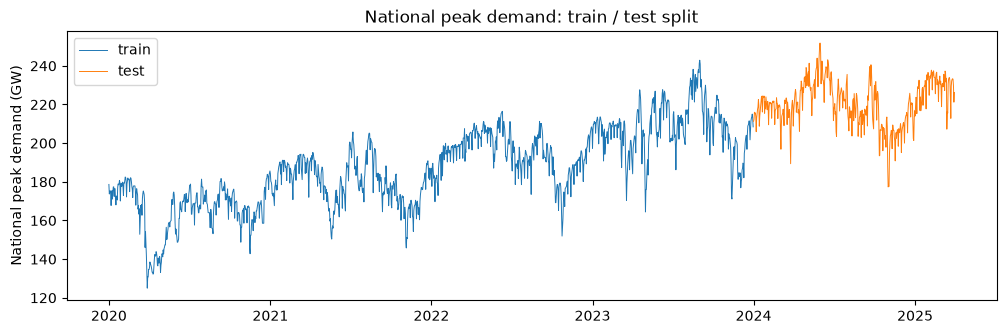

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(train.index, train / 1000, lw=0.7, label="train")
ax.plot(test.index, test / 1000, lw=0.7, label="test")
ax.set_ylabel("National peak demand (GW)")
ax.set_title("National peak demand: train / test split")
ax.legend()
plt.show()

## 3. Naive baselines (L0)

- **Persistence:** tomorrow = today (`lag=1`)
- **Last week:** tomorrow = the same weekday last week (`lag=7`)

In [5]:
baselines = {"Persistence (yesterday)": persistence(national, 1),
             "Last week": persistence(national, 7)}

# shift on the full series first, then cut to the test dates
for name, f in baselines.items():
    assert f.loc[TEST_START:].notna().all(), name
assert baselines["Persistence (yesterday)"].loc["2024-01-01"] == national.loc["2023-12-31"]

# persistence is the reference for skill, so its own skill is 0 by definition
base_mae = score(test, baselines["Persistence (yesterday)"].loc[test.index])["MAE"]
rows = {name: score(test, f.loc[test.index], base_mae) for name, f in baselines.items()}

results = pd.DataFrame(rows).T
results.round({"MAE": 0, "MAPE_%": 2, "RMSE": 0, "Skill": 3})

,MAE,MAPE_%,RMSE,Skill
Persistence (yesterday),4842.0,2.22,6501.0,0.000
Last week,6841.0,3.14,9178.0,-0.413


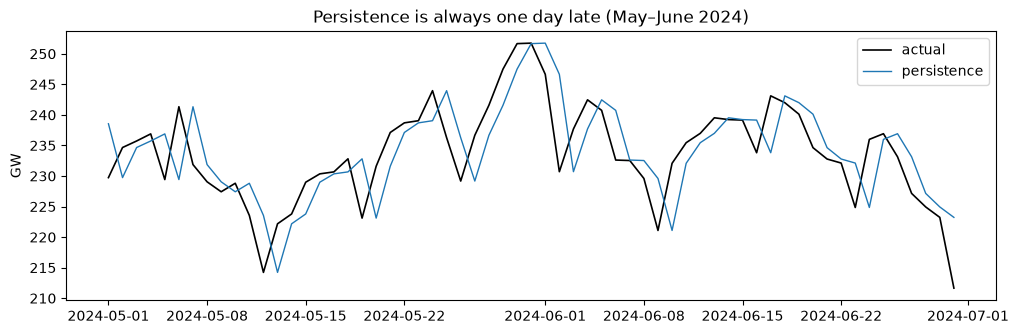

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.5))
window = slice("2024-05-01", "2024-06-30")       # includes the May 2024 heatwave
ax.plot(national.loc[window] / 1000, color="black", lw=1.2, label="actual")
ax.plot(baselines["Persistence (yesterday)"].loc[window] / 1000, lw=1, label="persistence")
ax.set_ylabel("GW")
ax.set_title("Persistence is always one day late (May–June 2024)")
ax.legend()
plt.show()

## 4. Why is "last week" worse than "yesterday"?

Demand has a weekly pattern (Sundays are ~7 GW lower), so "same weekday last week" sounds smart. Break the errors down by weekday to see what each baseline gets wrong.

In [7]:
err = pd.DataFrame({name: (test - f.loc[test.index]).abs() for name, f in baselines.items()})
by_day = err.groupby(err.index.day_name()).mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
(by_day / 1000).round(2).rename(columns=lambda c: c + " MAE (GW)")

,Persistence (yesterday) MAE (GW),Last week MAE (GW)
Date,,
Monday,10.21,6.65
Tuesday,2.72,5.77
Wednesday,2.79,5.31
Thursday,3.39,6.38
Friday,3.22,7.73
Saturday,3.24,8.55
Sunday,8.23,7.49


In [8]:
# how fast does a past day lose value? persistence error for lag 1..7
lag_mae = pd.Series({lag: score(test, persistence(national, lag).loc[test.index])["MAE"]
                     for lag in range(1, 8)}, name="MAE (GW)") / 1000
lag_mae.index.name = "lag (days)"
lag_mae.round(2)

lag (days)
1    4.84
2    6.46
3    7.19
4    7.48
5    7.77
6    7.68
7    6.84
Name: MAE (GW), dtype: float64

**Answer:** the error grows quickly as we look further back (4.8 GW at lag 1 → 7.8 GW at lag 5), then drops at lag 7 because the weekday matches again, but only to 6.8 GW, far from lag 1. Demand drifts with weather and season, and over a week that drift is bigger than the weekday effect. Yesterday knows this week's weather; last week doesn't.

Persistence's errors are largest on **Monday** (10.2 GW: Sunday's level is too low) and **Sunday** (8.2 GW: Saturday's level is too high), against ~3 GW on other days: exactly the weekday effect it ignores. Last week has no weekday problem but pays for a week of drift every day.

**Lesson for the next models:** combine the two: start from yesterday's level and correct for the weekday. That is what the L1–L2 models will learn.

## 5. State-level baselines

Part 2 forecasts every state (it feeds the dispatch model), so we need the baseline for each state too. MAPE lets us compare big and small states.

In [9]:
state_train, state_test = time_split(demand)
state_rows = {}
for state in demand.columns:
    f = persistence(demand[state], 1).loc[state_test.index]
    state_rows[state] = score(state_test[state], f)

state_base = pd.DataFrame(state_rows).T.sort_values("MAPE_%")
state_base["Mean_demand_MW"] = state_test.mean()
state_base.round({"MAE": 0, "MAPE_%": 2, "RMSE": 0, "Mean_demand_MW": 0})

,MAE,MAPE_%,RMSE,Mean_demand_MW
Chhattisgarh,123.0,2.38,179.0,5347.0
MP,337.0,2.54,535.0,14125.0
DD & DNH,33.0,2.66,48.0,1288.0
Rajasthan,403.0,2.74,590.0,15584.0
WR Maharashtra,717.0,2.77,996.0,26413.0
J&K(UT) & Ladakh(UT),75.0,2.79,122.0,2741.0
Andhra Pradesh,314.0,2.96,438.0,11115.0
NR UP,640.0,2.99,915.0,21945.0
Bihar,185.0,3.17,275.0,5908.0
Kerala,155.0,3.63,209.0,4372.0


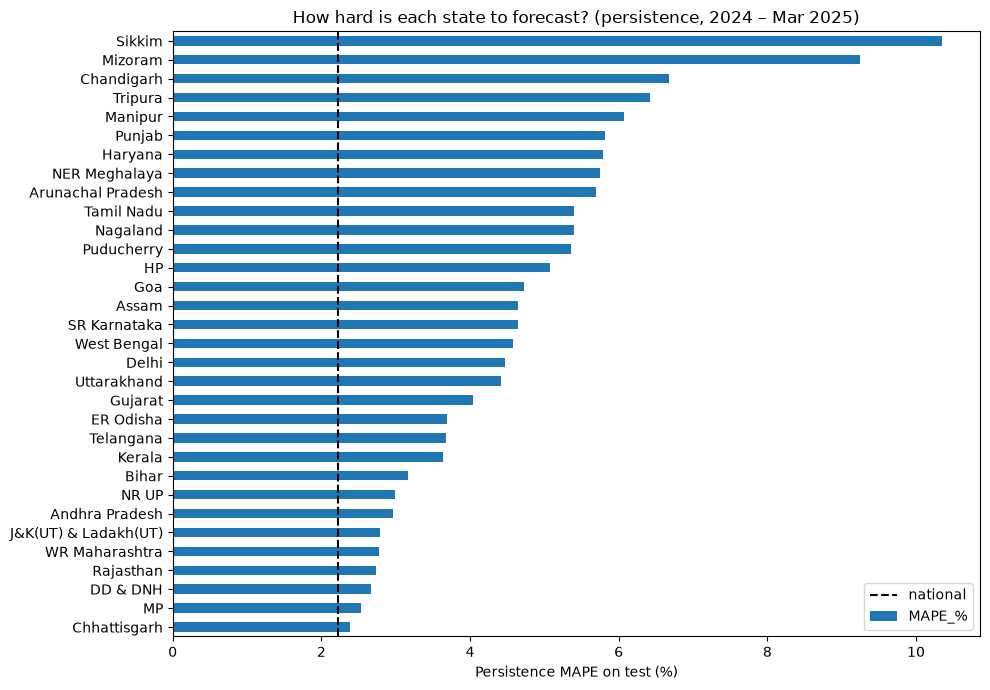

In [10]:
fig, ax = plt.subplots(figsize=(10, 7))
state_base["MAPE_%"].plot.barh(ax=ax)
ax.axvline(results.loc["Persistence (yesterday)", "MAPE_%"], color="black", ls="--",
           label="national")
ax.set_xlabel("Persistence MAPE on test (%)")
ax.set_title("How hard is each state to forecast? (persistence, 2024 – Mar 2025)")
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# sum of state errors vs national error: state errors partly cancel out when added up
sum_state_mae = state_base["MAE"].sum()
nat_mae = results.loc["Persistence (yesterday)", "MAE"]
print(f"sum of state MAEs: {sum_state_mae:,.0f} MW   national MAE: {nat_mae:,.0f} MW   "
      f"ratio {sum_state_mae / nat_mae:.2f}")

sum of state MAEs: 8,017 MW   national MAE: 4,842 MW   ratio 1.66


## Conclusions

- **The bar to beat: persistence, national MAPE ≈ 2.2%, MAE ≈ 4.8 GW** on the test period. Our target (skill ≥ 0.20) means MAE below ≈ 3.9 GW
- Last week is worse (MAPE ≈ 3.1%): a week of weather and seasonal drift costs more than the weekday effect it fixes
- Persistence fails most on Mondays and Sundays (8–10 GW vs ~3 GW): an easy win for a model that knows the weekday
- **States are much harder than the nation:** persistence MAPE ranges 2.4% (Chhattisgarh) to 9–10% (Mizoram, Sikkim), with most small UTs and North-East states at 5–7%; and state errors partly cancel when added up (sum of state MAEs is 1.66× the national MAE). Large farm-load states (Punjab, Haryana) and Tamil Nadu are also hard (5.4–5.8%), a hint that rainfall and farming-season features should help. Route B (state forecasts → dispatch) has to live with these bigger state errors
- Prices: the "actual" price will be re-made in Stage 2 with weather-based availability, so price baselines are computed there

**Next (Stage 1):** download daily weather for the 32 state capitals from Open-Meteo.